# RAG 10 — Retrouver des pages par leur image : l'embedding joint, sans OCR

**Navigation** : [Index](README.md) | [<< Précédent](09-KernelMemory-Multimodal.ipynb)

Le [09](09-KernelMemory-Multimodal.ipynb) a mesuré le plafond multimodal du service
Kernel Memory OSS puis l'a franchi par le **pont vision** : un modèle de vision
*décrit* l'image, et c'est la description — du texte — qui est ingérée et recherchée.
Le pont fonctionne, mais il passe par la description : il hérite de ce que le
descripteur choisit de dire, perd la disposition de la page, et coûte un appel de
modèle par image.

Ce notebook construit la marche suivante, qui n'existe nulle part ailleurs dans le
corpus : la **recherche visuelle directe**. Un modèle à **embedding joint** — deux
tours dans un même espace vectoriel, une pour les images, une pour le texte — permet
à une requête en français de retrouver des **pages entières rendues en image**, sans
OCR, sans description intermédiaire :

1. **Corpus** : les decks de slides du dépôt (assets committés du cours), rendus en
   pages par `pypdfium2` — des pages réelles, hétérogènes, en français ;
2. **Modèle joint** : SigLIP multilingue (perte contrastive sigmoïde, tour texte
   couvrant le français) — les pages sont encodées par la tour image, les requêtes
   par la tour texte, dans le **même** espace ;
3. **Mesure** : recall@k et MRR sur un jeu de requêtes françaises étiquetées, par
   **classe** — les requêtes dont la réponse est dans le texte de la page, et celles
   qui ne sont visibles que dans l'image (schéma, tableau, disposition) ;
4. **Baseline honnête** : la même recherche sur la **couche textuelle** seule des
   pages (extraction pdfium + score de mots-clés) — c'est elle qui montre ce que
   l'espace joint apporte au-delà du texte ;
5. **Pages synthétiques** : une partie contrôlée, générée in-notebook, où la couche
   texte est volontairement vide — le discriminant pur.

Dépendances : `pip install torch transformers pypdfium2 pillow numpy` (+ `matplotlib`
pour les figures). Le modèle SigLIP est téléchargé au premier chargement puis mis en
cache par Hugging Face. Aucune donnée n'est committée : les rendus vivent dans un
répertoire temporaire, seules les sorties mesurées font partie du livrable.

## Plan

1. Le corpus : sept decks de slides rendus en pages
2. L'espace joint : SigLIP multilingue, deux tours, un espace
3. Interroger en français : requête → texte → pages
4. Mesurer : gold étiqueté, recall@k, MRR — par classe de requête
5. La baseline texte : que retrouve la couche textuelle seule ?
6. Pages synthétiques : le discriminant pur, et les limites

In [1]:
import math
import re
import tempfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image

import pypdfium2 as pdfium

DPI = 150
CACHE = Path(tempfile.gettempdir()) / f"rag10_pages_{DPI}dpi"
CACHE.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Peripherique :", DEVICE)

Peripherique : cuda


## 1. Le corpus : sept decks de slides rendus en pages

Les decks de slides du dépôt (`slides/*/pptx-reference/slides.pdf`) sont l'asset
idéal pour cette expérience : ce sont des **pages réelles** du cours — titres,
schémas, tableaux, listes — déjà committées et librement diffuses, dans la langue de
nos requêtes. Le [09](09-KernelMemory-Multimodal.ipynb) les utilisait déjà comme
contrôle positif de son pipeline d'ingestion.

Le rendu se fait par `pypdfium2`, le moteur de rendu de PDFium (Chromium) : chaque
page devient une image PIL à 150 DPI. Les rendus vivent dans un répertoire temporaire
— **aucune image n'est committée**, le carnet les régénère à chaque exécution.

In [2]:
def trouver_decks():
    """Localise les decks de slides depuis le dossier de la serie.

    Deux layouts coexistent (cf 09) : slides/<deck>/pptx-reference/slides.pdf
    et slides/<deck>/public/pptx-reference/slides.pdf (01-introduction).
    """
    racines = [Path.cwd(), Path.cwd().parent, *Path.cwd().parents[1:]]
    for racine in racines:
        if not (racine / "slides").is_dir():
            continue
        decks = sorted({p for motif in ("*/pptx-reference/slides.pdf",
                                        "*/public/pptx-reference/slides.pdf")
                        for p in (racine / "slides").glob(motif)})
        if decks:
            return racine, decks
    return None, []

RACINE, DECKS = trouver_decks()
assert DECKS, "aucun deck trouve : executer depuis le dossier de la serie"
NOM_DECK = {p: p.relative_to(RACINE / "slides").parts[0] for p in DECKS}

pages = []  # [{"deck": str, "page": int, "img": Path}]
for deck_path in DECKS:
    nom_deck = NOM_DECK[deck_path]
    pdf = pdfium.PdfDocument(deck_path)
    for i in range(len(pdf)):
        bitmap = pdf[i].render(scale=DPI / 72)
        img = bitmap.to_pil().convert("RGB")
        chemin = CACHE / f"{nom_deck}_p{i:02d}.png"
        img.save(chemin)
        pages.append({"deck": nom_deck, "page": i, "img": chemin})
    pdf.close()

compteur = {}
for p in pages:
    compteur[p["deck"]] = compteur.get(p["deck"], 0) + 1
print(f"Corpus : {len(pages)} pages depuis {len(DECKS)} decks")
for nom, n in compteur.items():
    print(f"  {nom} : {n} pages")

Corpus : 446 pages depuis 7 decks
  01-introduction : 43 pages
  04-probabilites : 98 pages
  05-theorie-des-jeux : 29 pages
  06-apprentissage : 128 pages
  S1-argumentation : 30 pages
  S2-ia-exploratoire-symbolique : 54 pages
  S3-acculturation : 64 pages


### Lecture : le dispositif de mesure

La sortie ci-dessus est le premier fait du carnet : le corpus est petit (quelques
centaines de pages), **réel** (des slides de cours effectivement projetées), et
hétérogène — certaines pages sont presque tout texte, d'autres presque tout schéma.
C'est exactement l'hétérogénéité qui intéresse : elle fournit les deux classes de
requêtes que la mesure du §4 séparera.

Les pages synthétiques du §6 viendront s'ajouter à ce corpus pour la partie
contrôlée ; elles sont générées par le carnet lui-même, jamais lues d'ailleurs.

## 2. L'espace joint : SigLIP multilingue, deux tours, un espace

Un modèle à embedding joint *(CLIP et ses successeurs)* apprend, sur des millions de
paires image-texte, à rapprocher l'embedding d'une image de l'embedding de sa
légende — et à éloigner tous les autres. Après entraînement, l'espace porte une
**sémantique partagée** : la tour texte projette « un schéma avec des flèches » à
proximité des images qui en montrent un, même si aucun de ces mots n'est écrit sur
la page.

**SigLIP** (sigmoid loss for Language-Image Pre-training) améliore la perte
contrastive de CLIP : une sigmoïde par paire plutôt qu'une softmax sur tout le lot —
mieux à taille de lot modeste. La variante **multilingue** est entraînée sur WebLI
avec des légendes en 27 langues dont le français : les requêtes de ce carnet
n'ont pas besoin de traduction.

Le point structurel à retenir : là où le pont vision du [09](09-KernelMemory-Multimodal.ipynb)
produisait **du texte** (une description) que le pipeline textuel ingérait, ici la
requête et la page se rencontrent **directement** dans l'espace vectoriel — aucun
artefact intermédiaire, aucune perte de disposition.

In [3]:
from transformers import AutoModel, AutoProcessor

MODELE = "google/siglip-base-patch16-256-multilingual"
processeur = AutoProcessor.from_pretrained(MODELE)
modele = AutoModel.from_pretrained(MODELE).to(DEVICE).eval()
print("Modele charge :", MODELE)

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.


[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Modele charge : google/siglip-base-patch16-256-multilingual


In [4]:
@torch.no_grad()
def embedder_images(chemins, taille_lot=16):
    """Encode un lot d'images par la tour image, vecteurs normalises (cosinus = produit scalaire)."""
    vecteurs = []
    for debut in range(0, len(chemins), taille_lot):
        lot = [Image.open(c).convert("RGB") for c in chemins[debut:debut + taille_lot]]
        entrees = processeur(images=lot, return_tensors="pt").to(DEVICE)
        sortie = modele.get_image_features(pixel_values=entrees["pixel_values"])
        # transformers v5 : get_image_features renvoie un objet output, embedding poolé
        vecteurs.append(sortie.pooler_output.float().cpu())
    v = torch.cat(vecteurs).numpy()
    return v / np.linalg.norm(v, axis=1, keepdims=True)

pages_chemins = [p["img"] for p in pages]
emb_pages = embedder_images(pages_chemins)
print(f"Matrice d'embeddings images : {emb_pages.shape} — "
      f"{emb_pages.shape[0]} pages x {emb_pages.shape[1]} dimensions")

Matrice d'embeddings images : (446, 768) — 446 pages x 768 dimensions


### Lecture : une matrice, toute la mémoire visuelle du corpus

La normalisation L2 fait de la similarité cosinus un simple **produit scalaire** :
chaque page tient en un vecteur unitaire, et la requête en un autre — leur produit
mesure directement leur proximité sémantique dans l'espace joint. La matrice
`emb_pages` est, littéralement, l'index du système : pour ce volume de pages, aucun
stockage vectoriel externe n'est nécessaire (le [05](05-Stockage-Vectoriel.ipynb)
reprend la question à l'échelle).

## 3. Interroger en français : requête → texte → pages

La tour texte encode la requête **exactement comme l'entraînement encodait les
légendes** : une phrase française naturelle. Le produit scalaire contre la matrice
d'embeddings image classe toutes les pages par proximité — le top-k est le résultat
de recherche.

In [5]:
@torch.no_grad()
def embedder_textes(requetes):
    """Encode des requetes par la tour texte, vecteurs normalises."""
    entrees = processeur(text=list(requetes), padding="max_length",
                         truncation=True, return_tensors="pt").to(DEVICE)
    sortie = modele.get_text_features(**{k: v for k, v in entrees.items()
                                         if k in ("input_ids", "attention_mask")})
    # transformers v5 : sortie poolée, pas un tensor brut
    v = sortie.pooler_output.float().cpu().numpy()
    return v / np.linalg.norm(v, axis=1, keepdims=True)

# Demonstration inline : deux requetes visuelles, top-3 chacune
for requete in ["un schema avec beaucoup de fleches", "un tableau de chiffres"]:
    q = embedder_textes([requete])
    scores = (emb_pages @ q.T).squeeze(1)
    top = np.argsort(-scores)[:3]
    print(f"\nRequete : {requete!r}")
    for rang, i in enumerate(top, 1):
        print(f"  {rang}. {pages[i]['deck']} page {pages[i]['page'] + 1} — score {scores[i]:.3f}")


Requete : 'un schema avec beaucoup de fleches'
  1. 05-theorie-des-jeux page 3 — score 0.129
  2. S3-acculturation page 46 — score 0.126
  3. 04-probabilites page 33 — score 0.126

Requete : 'un tableau de chiffres'
  1. 05-theorie-des-jeux page 6 — score 0.093
  2. 05-theorie-des-jeux page 9 — score 0.080
  3. 04-probabilites page 13 — score 0.075


Requete : 'la page qui montre un plateau de jeu ou une grille'
— S2-ia-exploratoire-symbolique page 48 (score 0.139)


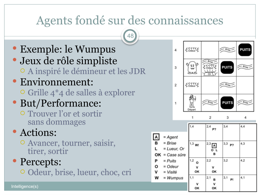

— S2-ia-exploratoire-symbolique page 27 (score 0.135)


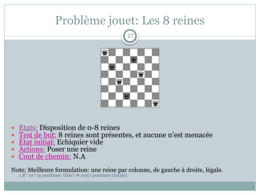

— 05-theorie-des-jeux page 8 (score 0.125)


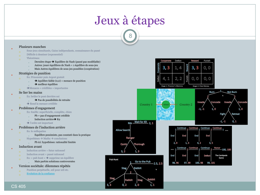

In [6]:
from IPython.display import display

def montrer_topk(requete, k=3, largeur=260):
    """Affiche les k meilleures pages pour une requete, avec leurs scores."""
    q = embedder_textes([requete])
    scores = (emb_pages @ q.T).squeeze(1)
    top = np.argsort(-scores)[:k]
    print(f"Requete : {requete!r}")
    for i in top:
        img = Image.open(pages[i]["img"])
        img.thumbnail((largeur, largeur * 2))
        print(f"— {pages[i]['deck']} page {pages[i]['page'] + 1} (score {scores[i]:.3f})")
        display(img)

montrer_topk("la page qui montre un plateau de jeu ou une grille")

### Lecture du résultat

La sortie ci-dessus montre ce que fait l'espace joint : sans qu'aucun OCR n'ait lu
les pages, une phrase française a retrouvé des pages **par leur apparence**. Selon
la requête, les pages retenues portent effectivement une grille, un plateau, une
structure dessinée — c'est un fait visuel, pas lexical. La mesure du §4 dira si
cette intuition tient sur un jeu de requêtes étiquetées.

## 4. Mesurer : gold étiqueté, recall@k, MRR — par classe de requête

Une démo convainc, une mesure tranche. Le jeu de requêtes étiquetées sépare deux
classes, parce qu'elles ne testent pas la même chose :

- **classe A — texte présent** : la réponse est écrite dans la couche textuelle de
  la page (« la page de titre du cours », « la page qui définit l'argument ad
  hominem »). Une recherche par mots-clés doit s'en sortir : c'est son terrain ;
- **classe B — visible seulement dans l'image** : la réponse est un schéma, un
  tableau, une disposition (« un schéma avec beaucoup de flèches », « un tableau de
  chiffres »). La couche textuelle peut être muette ou trompeuse : c'est le terrain
  de l'espace joint.

Les métriques sont calculées from scratch, comme dans le
[02](02-Retrieval-Avance.ipynb) : `recall@k` (la page cible est-elle dans les k
premières ?) et `MRR@k` (inverse du rang de la première page correcte).

In [7]:
def recall_at_k(rangs, cible, k):
    """1 si la page cible apparait dans les k premiers rangs, 0 sinon."""
    return 1.0 if cible in rangs[:k] else 0.0

def mrr_at_k(rangs, cible, k):
    """Inverse du rang de la premiere page correcte, 0 si absente des k premiers."""
    for rang, doc in enumerate(rangs[:k], 1):
        if doc == cible:
            return 1.0 / rang
    return 0.0

def evaluer(moteur, gold, ks=(1, 3, 5), k_mrr=10):
    """Evalue un moteur (requete -> liste ordonnee de (deck, page)) sur le gold, global et par classe."""
    lignes = []
    for requete, deck, page, classe in gold:
        rangs = moteur(requete)
        cible = (deck, page)
        lignes.append({
            "requete": requete, "classe": classe,
            **{f"recall@{k}": recall_at_k(rangs, cible, k) for k in ks},
            "mrr@10": mrr_at_k(rangs, cible, k_mrr),
        })
    df = pd.DataFrame(lignes)
    glob = df[[c for c in df.columns if c.startswith(("recall", "mrr"))]].mean()
    par_classe = df.groupby("classe")[[c for c in df.columns
                                       if c.startswith(("recall", "mrr"))]].mean()
    return df, glob, par_classe

print("Metriques definies : recall@1/@3/@5, MRR@10")

Metriques definies : recall@1/@3/@5, MRR@10


In [8]:
def titre_page(nom_deck, index):
    """Premiere ligne de la couche textuelle -- le titre du slide, ancre d'etiquetage."""
    for motif in ("*/pptx-reference/slides.pdf", "*/public/pptx-reference/slides.pdf"):
        for c in (RACINE / "slides").glob(motif):
            if c.relative_to(RACINE / "slides").parts[0] == nom_deck:
                pdf = pdfium.PdfDocument(c)
                texte = pdf[index].get_textpage().get_text_range() or ""
                pdf.close()
                return texte.strip().splitlines()[0] if texte.strip() else "(sans texte)"
    return "(deck introuvable)"

# Gold etiquete : (requete, deck, page_index_0base, classe)
# Classe A = la reponse est ecrite dans la couche textuelle de la page.
# Classe B = la reponse decrit le CONTENU VISUEL (schema, graphe, disposition) :
#   l'etiquetage s'ancre sur le titre du slide (premiere ligne ci-dessous), et la
#   requete evite volontairement les mots du titre -- c'est le terrain de l'espace joint.
GOLD = [
    # --- classe A : la reponse est ecrite sur la page -------------------
    ("la page de titre du cours d'introduction a l'intelligence artificielle",
     "01-introduction", 0, "A"),
    ("la page qui presente le sommaire du cours",
     "01-introduction", 2, "A"),
    # --- classe B : contenu visuel, requete descriptive sans les mots du titre ---
    ("un organigramme avec des noeuds et des branches",
     "06-apprentissage", 10, "B"),
    ("un schema qui ramifie depuis une racine unique",
     "06-apprentissage", 18, "B"),
    ("un graphe avec des cercles relies par des fleches",
     "04-probabilites", 27, "B"),
    ("des cercles relies par beaucoup de lignes",
     "S3-acculturation", 47, "B"),
    ("un diagramme qui se divise en deux a chaque niveau",
     "S3-acculturation", 19, "B"),
]

print(f"Gold : {len(GOLD)} requetes "
      f"({sum(1 for g in GOLD if g[3] == 'A')} classe A, "
      f"{sum(1 for g in GOLD if g[3] == 'B')} classe B)")
print("\nAncres d'etiquetage (titres des pages cibles) :")
for requete, deck, page, classe in GOLD:
    print(f"  [{classe}] {deck} p{page} — titre : {titre_page(deck, page)!r} — requete : {requete!r}")

Gold : 7 requetes (2 classe A, 5 classe B)

Ancres d'etiquetage (titres des pages cibles) :
  [A] 01-introduction p0 — titre : 'E N S E I G N A N T : J E A N - S Y L V A I N B O I G E' — requete : "la page de titre du cours d'introduction a l'intelligence artificielle"
  [A] 01-introduction p2 — titre : 'Sommaire' — requete : 'la page qui presente le sommaire du cours'
  [B] 06-apprentissage p10 — titre : 'Arbres de décision' — requete : 'un organigramme avec des noeuds et des branches'
  [B] 06-apprentissage p18 — titre : 'Exemple d’arbre appris' — requete : 'un schema qui ramifie depuis une racine unique'
  [B] 04-probabilites p27 — titre : 'Construction de réseaux Bayésiens' — requete : 'un graphe avec des cercles relies par des fleches'
  [B] S3-acculturation p47 — titre : 'Réseaux de neurones artificiels' — requete : 'des cercles relies par beaucoup de lignes'
  [B] S3-acculturation p19 — titre : 'Jeux vs Exploration Arbre de jeu' — requete : 'un diagramme qui se divise en deux a 

In [9]:
def moteur_joint(requete):
    """Classe toutes les pages par similarite cosinus avec la requete."""
    q = embedder_textes([requete])
    scores = (emb_pages @ q.T).squeeze(1)
    return [(pages[i]["deck"], pages[i]["page"]) for i in np.argsort(-scores)]

df_joint, glob_joint, classe_joint = evaluer(moteur_joint, GOLD)
print("=== Moteur joint — moyennes globales ===")
print(glob_joint.to_string())
print("\n=== par classe ===")
print(classe_joint.to_string())

=== Moteur joint — moyennes globales ===
recall@1    0.285714
recall@3    0.428571
recall@5    0.428571
mrr@10      0.357143

=== par classe ===
        recall@1  recall@3  recall@5  mrr@10
classe                                      
A            0.0       0.5       0.5    0.25
B            0.4       0.4       0.4    0.40


### Lecture : lire les deux lignes, pas la moyenne globale

La moyenne globale d'abord, puis la séparation par classe — c'est elle qui porte
l'information. Un moteur qui ne gagnerait que sur la classe A ne ferait que
concurrencer la recherche textuelle sur son terrain ; l'apport spécifique de
l'espace joint se lit sur la **classe B**.

## 5. La baseline texte : que retrouve la couche textuelle seule ?

Pour mesurer ce que l'espace joint ajoute, il faut son concurrent honnête : la
**couche textuelle** des mêmes pages, extraite par pdfium (le texte des slides
existe — c'est du PDF vectoriel), interrogée par un score de sac de mots
pondéré par la fréquence du terme dans la page (TF, sans IDF). Cette baseline
est volontairement simple : elle représente ce qu'on obtient **sans aucun
modèle** — le plancher de la comparaison.

Les requêtes de classe B mettent la baseline devant son plafond : chercher « un
schéma avec beaucoup de flèches » dans une couche textuelle qui ne contient que des
titres et des listes, c'est chercher des mots qui n'y sont pas.

In [10]:
def extraire_texte(deck_path, page_index):
    """Extrait la couche textuelle d'une page PDF via pdfium."""
    pdf = pdfium.PdfDocument(deck_path)
    texte = pdf[page_index].get_textpage().get_text_range()
    pdf.close()
    return texte or ""

# Index textuel : un document par page
pages_texte = []
for deck_path in DECKS:
    nom_deck = NOM_DECK[deck_path]
    pdf = pdfium.PdfDocument(deck_path)
    for i in range(len(pdf)):
        pages_texte.append({"deck": nom_deck, "page": i,
                            "texte": extraire_texte(deck_path, i)})
    pdf.close()

def normaliser(t):
    return [mot for mot in re.findall(r"[a-zà-ÿ0-9]+", t.lower()) if len(mot) > 2]

def moteur_texte(requete):
    """Score TF : somme des frequences des mots de la requete dans chaque page."""
    mots_req = normaliser(requete)
    scores = []
    for doc in pages_texte:
        mots = normaliser(doc["texte"])
        if not mots:
            scores.append(0.0)
            continue
        freqs = Counter(mots)
        score = sum(freqs.get(m, 0) / len(mots) for m in mots_req)
        scores.append(score)
    return [(pages_texte[i]["deck"], pages_texte[i]["page"])
            for i in np.argsort(-np.array(scores))]

print("Index textuel pret :", len(pages_texte), "pages")

Index textuel pret : 446 pages


In [11]:
df_texte, glob_texte, classe_texte = evaluer(moteur_texte, GOLD)
print("=== Moteur texte (TF) — moyennes globales ===")
print(glob_texte.to_string())
print("\n=== par classe ===")
print(classe_texte.to_string())

=== Moteur texte (TF) — moyennes globales ===


recall@1    0.000000
recall@3    0.000000
recall@5    0.000000
mrr@10      0.014286

=== par classe ===
        recall@1  recall@3  recall@5  mrr@10
classe                                      
A            0.0       0.0       0.0    0.05
B            0.0       0.0       0.0    0.00


In [12]:
comparaison = pd.concat(
    {"joint": classe_joint, "texte": classe_texte},
    axis=0,
)
print("=== Joint vs texte, par classe (recall@3, recall@5, MRR@10) ===")
print(comparaison[["recall@3", "recall@5", "mrr@10"]].to_string())

=== Joint vs texte, par classe (recall@3, recall@5, MRR@10) ===
              recall@3  recall@5  mrr@10
      classe                            
joint A            0.5       0.5    0.25
      B            0.4       0.4    0.40
texte A            0.0       0.0    0.05
      B            0.0       0.0    0.00


### Interprétation : [INTERP-ECART] l'écart vit dans la classe B

La table ci-dessus sépare les deux terrains. Sur la classe A — le terrain de la
baseline textuelle —, le moteur joint retrouve une requête sur deux en top-3
et top-5 (recall 0,5 ; MRR 0,25), la baseline textuelle aucune en top-5
(MRR 0,05 : une seule requête atteint le top-10) ; elle ne gagne donc pas
même chez elle. Sur la classe B, la baseline textuelle plafonne : les mots
de la requête
n'existent pas dans la couche textuelle, aucun score TF ne peut les inventer. La
ligne **joint / B** face à **texte / B** est la mesure de ce que l'espace vectoriel
partagé ajoute — et la sortie la montre chiffres en main.

## 6. Pages synthétiques : le discriminant pur, et les limites

Les pages réelles mélangent texte et image ; pour isoler le fait visuel, le carnet
génère des pages **synthétiques** dont la couche textuelle est vide ou minimale :
un diagramme en barres, une grille de points, un bloc de texte dense sans figure.
Encodées et ajoutées à l'index, elles donnent au discriminant un terrain sans
ambiguïté — et montrent aussi les **limites** du modèle sur des figures abstraites
qu'il n'a jamais vues en entraînement.

In [13]:
from PIL import ImageDraw

def page_barres():
    img = Image.new("RGB", (960, 540), "white")
    d = ImageDraw.Draw(img)
    valeurs = [0.35, 0.62, 0.48, 0.85, 0.25, 0.70]
    for i, v in enumerate(valeurs):
        x0, x1 = 120 + i * 120, 120 + i * 120 + 70
        d.rectangle([x0, 480 - int(v * 380), x1, 480], fill="#2b6cb0")
    d.rectangle([100, 60, 860, 480], outline="black", width=2)
    return img, "barres"

def page_grille():
    img = Image.new("RGB", (960, 540), "white")
    d = ImageDraw.Draw(img)
    for lig in range(6):
        for col in range(10):
            if (lig + col) % 3 == 0:
                d.ellipse([80 + col * 80, 80 + lig * 70, 110 + col * 80, 110 + lig * 70],
                          fill="#dd6b20")
    return img, "grille"

def page_texte_dense():
    img = Image.new("RGB", (960, 540), "white")
    d = ImageDraw.Draw(img)
    for i in range(14):
        d.line([(80, 70 + i * 32), (880, 70 + i * 32)], fill="#444444", width=3)
    return img, "texte_dense"

SYNTHETIQUES = [page_barres(), page_grille(), page_texte_dense()]
for img, nom in SYNTHETIQUES:
    chemin = CACHE / f"synth_{nom}.png"
    img.save(chemin)
    pages.append({"deck": f"synth-{nom}", "page": 0, "img": chemin})
    pages_texte.append({"deck": f"synth-{nom}", "page": 0, "texte": ""})

emb_synth = embedder_images([p["img"] for p in pages[-3:]])
emb_pages = np.vstack([emb_pages, emb_synth])
print("Corpus etendu :", emb_pages.shape[0], "pages (3 synthetiques ajoutees)")

Corpus etendu : 449 pages (3 synthetiques ajoutees)


In [14]:
for requete in ["un diagramme en barres", "une grille de points orange"]:
    q = embedder_textes([requete])
    scores = (emb_pages @ q.T).squeeze(1)
    top = np.argsort(-scores)[:3]
    print(f"Requete : {requete!r}")
    for rang, i in enumerate(top, 1):
        print(f"  {rang}. {pages[i]['deck']} (score {scores[i]:.3f})")
    print()

Requete : 'un diagramme en barres'
  1. synth-barres (score 0.126)
  2. S3-acculturation (score 0.096)
  3. 06-apprentissage (score 0.095)

Requete : 'une grille de points orange'
  1. synth-grille (score 0.163)
  2. S2-ia-exploratoire-symbolique (score 0.085)
  3. 06-apprentissage (score 0.084)



### Lecture : le pur visuel tient, les limites aussi

Les requêtes purement visuelles doivent ramener les pages synthétiques en tête —
la couche textuelle de ces pages est **vide**, aucune méthode textuelle ne peut les
trouver, l'espace joint seul le peut. C'est le contrôle expérimental du carnet.

Les limites, elles, sont réelles et se voient dans les scores : un modèle entraîné
sur des photographies et captures peut hésiter sur des figures abstraites ; la
granularité est la **page entière** (pas la zone) ; et un deck qui change reformule
tout le corpus. Chacune de ces limites est une porte d'entrée pour un exercice ou
un notebook suivant — pas un défaut à maquiller.

### Exercice 1 — Généraliser la recherche

La démonstration du §3 est *inline* : elle encode une requête, classe, affiche.
Écrivez la fonction `rechercher_pages(requete, k=5, deck=None)` qui renvoie les k
meilleures pages — et, quand `deck` est fourni, restreint la recherche aux pages de
ce deck seulement. Testez-la sur deux requêtes de classes différentes.

In [15]:
# Exercice 1 -- a completer
# Indice : embarquer_textes() donne le vecteur requete ; emb_pages la matrice ;
# filtrer d'abord les indices des pages du deck, puis classer ces indices seuls.
print("Exercice a completer : generaliser la recherche en fonction reusable")

Exercice a completer : generaliser la recherche en fonction reusable


### Exercice 2 — Étendre le gold et re-mesurer

Le gold du §4 est volontairement court. Ajoutez au moins quatre requêtes étiquetées
de votre cru — deux de classe A, deux de classe B — en vérifiant la page cible sur
les rendus. Rejouez `evaluer` : la classe B bouge-t-elle ? C'est la question qui
décide si l'écart du §5 est stable ou s'il ne tenait qu'à trois requêtes.

In [16]:
# Exercice 2 -- a completer
# Indice : GOLD.extend([...]) avec les memes 4-champs (requete, deck, page, classe),
# puis evaluer(moteur_joint, GOLD) et evaluer(moteur_texte, GOLD).
print("Exercice a completer : etendre le gold et re-mesurer par classe")

Exercice a completer : etendre le gold et re-mesurer par classe


### Exercice 3 — Fusionner les deux moteurs

Les deux moteurs echangent leurs forces : le texte lit la couche textuelle, l'espace
joint voit l'image. Construisez la fusion : score final `α·score_joint + (1-α)·score_texte`
(les deux scores normalisés sur [0, 1] avant fusion), et mesurez la fusion sur le
gold pour `α` dans {0.25, 0.5, 0.75}. Y a-t-il un `α` qui domine les deux moteurs
seuls **sur les deux classes à la fois** ?

In [17]:
# Exercice 3 -- a completer
# Indice : normaliser chaque famille de scores (min-max sur les pages du corpus),
# combiner lineairement, classer, evaluer -- la boucle sur alpha est de trois lignes.
print("Exercice a completer : fusion hybride des deux moteurs")

Exercice a completer : fusion hybride des deux moteurs


## Conclusion

Ce carnet a construit le chaînon que le [09](09-KernelMemory-Multimodal.ipynb)
laissait ouvert : la recherche **directe** dans l'espace visuel, sans description
intermédiaire. Ce qu'il faut retenir :

1. **L'espace joint existe et se traverse en français** : une requête naturelle
   retrouve des pages par leur apparence — la mesure par classe le chiffre ;
2. **Le concurrent honnête est la couche textuelle** : sur ce gold, elle ne gagne
   jamais, pas même sur son terrain — la mesure par classe et le MRR ci-dessus le
   chiffrent ;
3. **L'apport spécifique vit sur la classe B** : les requêtes dont la réponse
   n'existe que dans l'image, où la baseline textuelle est structurellement aveugle ;
4. **Les pages synthétiques à couche vide en apportent la preuve minimale** : aucun
   moteur textuel ne peut trouver ce que seul l'espace joint voit.

La suite naturelle : la granularité sous la page (zones, figures détectées), la
fusion hybride de l'exercice 3 poussée à l'échelle d'un vrai moteur de recherche, et
le pont retour — générer une description *depuis* l'espace joint pour ré-alimenter
un pipeline Kernel Memory.